In [31]:
import joblib

# Load the bundle
bundle = joblib.load("../models/tuned_models_bundle.pkl")

# Check what keys are inside
print("Top-level keys:", bundle.keys())
print("Available models:", bundle["models"].keys())

# Grab our Champion LightGBM model directly
champion_lgbm = bundle["models"]["LightGBM (Weighted)"]["best_estimator"]
print("Champion LightGBM Parameters:", champion_lgbm.get_params())
print("Calibrated Max-F1 Threshold:",
      bundle["models"]["LightGBM (Weighted)"]["opt_f1_threshold"])

Top-level keys: dict_keys(['X_test', 'y_test', 'models'])
Available models: dict_keys(['Random Forest (Weighted)', 'Random Forest (SMOTE)', 'XGBoost (Weighted)', 'LightGBM (Weighted)'])
Champion LightGBM Parameters: {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 0.8, 'importance_type': 'split', 'learning_rate': 0.03, 'max_depth': -1, 'min_child_samples': 10, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 100, 'n_jobs': -1, 'num_leaves': 63, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.9, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'scale_pos_weight': np.float64(3.9029213483146066), 'verbose': -1}
Calibrated Max-F1 Threshold: 0.57


In [ ]:
# ==========================================
# CELL 1: Load & Inspect Week 4 Tuning Leaderboard
# ==========================================
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Week 4 tuning and threshold calibration results
tuning_df = pd.read_csv("../data/tuning_results.csv")
bundle = joblib.load("../models/tuned_models_bundle.pkl")

print("--- Week 4 Complete Progression Table (Baseline -> Tuned -> Calibrated) ---")
display(tuning_df.round(4))

print("\n--- Top Performing Configurations Ranked by F1-Score ---")
top_f1 = tuning_df.sort_values(
    by="F1_Score", ascending=False).reset_index(drop=True)
display(top_f1.round(4))

--- Week 4 Complete Progression Table (Baseline -> Tuned -> Calibrated) ---


,Model,Stage,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Random Forest (Weighted),1. Baseline (Default @ 0.50),0.50,0.8262,0.5891,0.4874,0.5335,0.8111,0.5760
1,Random Forest (Weighted),2. Tuned (Default @ 0.50),0.50,0.8112,0.5324,0.6061,0.5669,0.8158,0.5928
2,Random Forest (Weighted),3. Tuned + Max-F1 Thresh (0.50),0.50,0.8112,0.5324,0.6061,0.5669,0.8158,0.5928
3,Random Forest (Weighted),4. Tuned + Clinical Safety Thresh (0.44),0.44,0.7757,0.4663,0.6960,0.5584,0.8158,0.5928
4,Random Forest (SMOTE),1. Baseline (Default @ 0.50),0.50,0.8145,0.5488,0.5054,0.5262,0.8055,0.5485
5,Random Forest (SMOTE),2. Tuned (Default @ 0.50),0.50,0.8163,0.5485,0.5594,0.5539,0.8110,0.5740
6,Random Forest (SMOTE),3. Tuned + Max-F1 Thresh (0.48),0.48,0.8123,0.5348,0.6079,0.5690,0.8110,0.5740
7,Random Forest (SMOTE),4. Tuned + Clinical Safety Thresh (0.44),0.44,0.7870,0.4835,0.6583,0.5575,0.8110,0.5740
8,XGBoost (Weighted),1. Baseline (Default @ 0.50),0.50,0.7999,0.5084,0.5432,0.5252,0.7927,0.5369
9,XGBoost (Weighted),2. Tuned (Default @ 0.50),0.50,0.7874,0.4843,0.6637,0.5599,0.8121,0.5981



--- Top Performing Configurations Ranked by F1-Score ---


,Model,Stage,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,LightGBM (Weighted),3. Tuned + Max-F1 Thresh (0.57),0.57,0.8204,0.5561,0.5881,0.5717,0.8143,0.6008
1,Random Forest (SMOTE),3. Tuned + Max-F1 Thresh (0.48),0.48,0.8123,0.5348,0.6079,0.5690,0.8110,0.5740
2,Random Forest (Weighted),2. Tuned (Default @ 0.50),0.50,0.8112,0.5324,0.6061,0.5669,0.8158,0.5928
3,Random Forest (Weighted),3. Tuned + Max-F1 Thresh (0.50),0.50,0.8112,0.5324,0.6061,0.5669,0.8158,0.5928
4,XGBoost (Weighted),3. Tuned + Max-F1 Thresh (0.55),0.55,0.8105,0.5308,0.6043,0.5652,0.8121,0.5981
5,LightGBM (Weighted),1. Baseline (Default @ 0.50),0.50,0.7878,0.4850,0.6709,0.5630,0.8132,0.5966
6,LightGBM (Weighted),4. Tuned + Clinical Safety Thresh (0.51),0.51,0.7933,0.4946,0.6529,0.5628,0.8143,0.6008
7,XGBoost (Weighted),4. Tuned + Clinical Safety Thresh (0.51),0.51,0.7929,0.4939,0.6529,0.5624,0.8121,0.5981
8,XGBoost (Weighted),2. Tuned (Default @ 0.50),0.50,0.7874,0.4843,0.6637,0.5599,0.8121,0.5981
9,LightGBM (Weighted),2. Tuned (Default @ 0.50),0.50,0.7878,0.4848,0.6601,0.5590,0.8143,0.6008


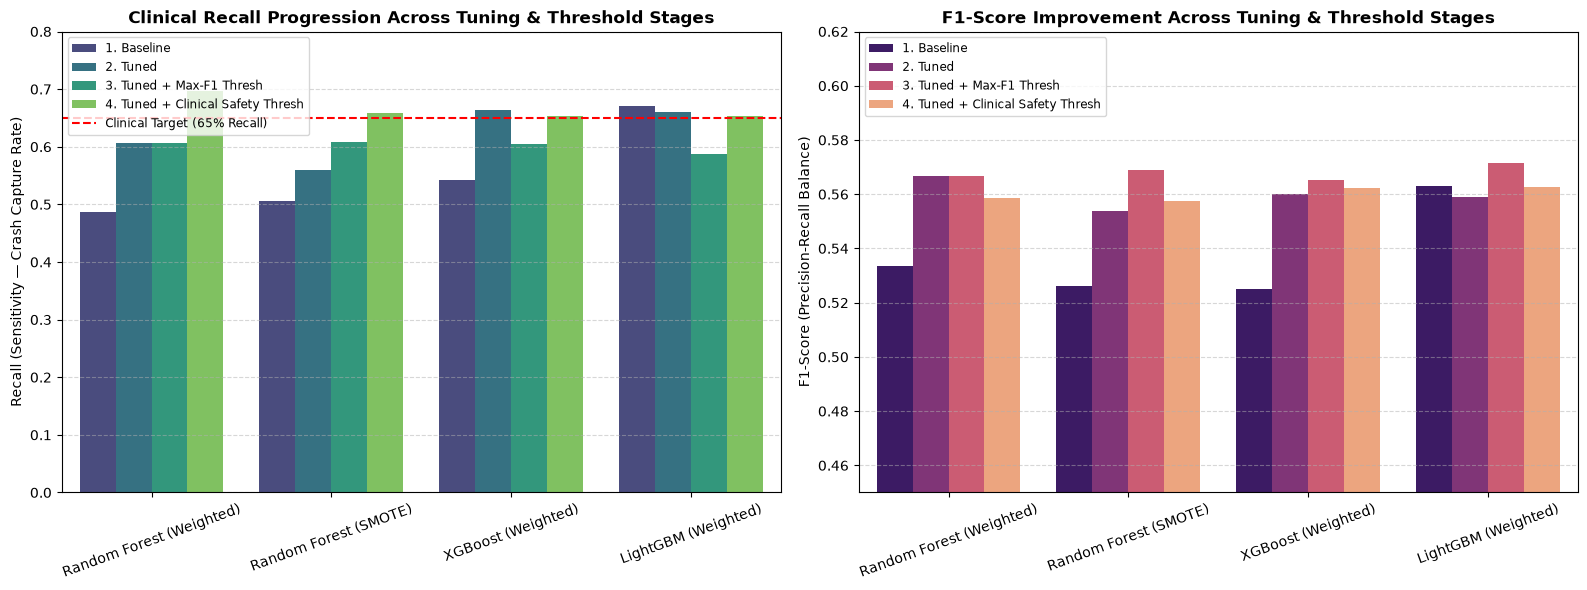

In [ ]:
# ==========================================
# CELL 2: Baseline vs. Tuned vs. Calibrated Gains
# ==========================================
# Normalize stage names for clean legend grouping
plot_df = tuning_df.copy()
plot_df["Stage_Clean"] = plot_df["Stage"].apply(lambda s: s.split(" (")[0])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Clinical Recall Progression across the 4 Stages
sns.barplot(
    data=plot_df, x="Model", y="Recall", hue="Stage_Clean",
    palette="viridis", ax=axes[0]
)
axes[0].axhline(y=0.65, color="red", linestyle="--", lw=1.5,
                label="Clinical Target (65% Recall)")
axes[0].set_title("Clinical Recall Progression Across Tuning & Threshold Stages",
                  fontsize=12.5, fontweight="bold")
axes[0].set_ylabel("Recall (Sensitivity — Crash Capture Rate)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0, 0.80)
axes[0].legend(loc="upper left", fontsize=8.5)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# 2. F1-Score Progression across the 4 Stages
sns.barplot(
    data=plot_df, x="Model", y="F1_Score", hue="Stage_Clean",
    palette="magma", ax=axes[1]
)
axes[1].set_title("F1-Score Improvement Across Tuning & Threshold Stages",
                  fontsize=12.5, fontweight="bold")
axes[1].set_ylabel("F1-Score (Precision-Recall Balance)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0.45, 0.62)
axes[1].legend(loc="upper left", fontsize=8.5)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

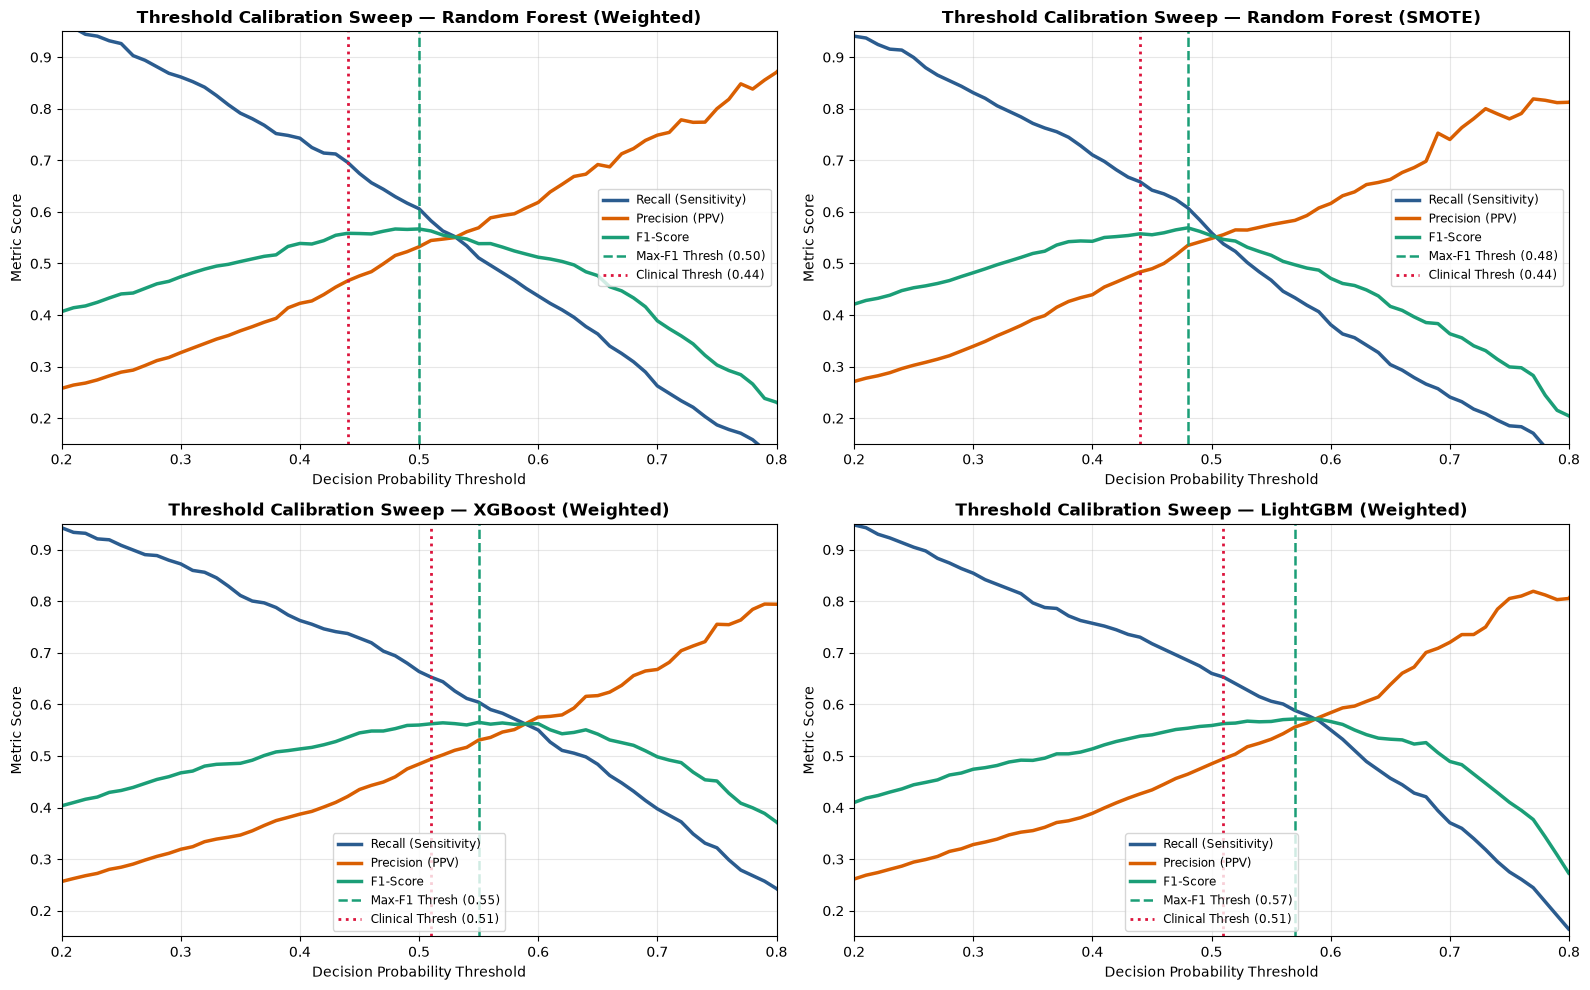

In [ ]:
# ==========================================
# CELL 3: Decision Threshold Sweep Curves (0.20 to 0.80)
# ==========================================
from sklearn.metrics import precision_score, recall_score, f1_score

y_test = bundle["y_test"]
thresholds = np.arange(0.20, 0.81, 0.01)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, model_data) in enumerate(bundle["models"].items()):
    y_prob = model_data["y_prob_test"]
    opt_t = model_data["opt_f1_threshold"]
    clin_t = model_data["clinical_threshold"]

    prec_list, rec_list, f1_list = [], [], []
    for t in thresholds:
        preds = (y_prob >= t).astype(int)
        prec_list.append(precision_score(y_test, preds, zero_division=0))
        rec_list.append(recall_score(y_test, preds, zero_division=0))
        f1_list.append(f1_score(y_test, preds, zero_division=0))

    ax = axes[idx]
    ax.plot(thresholds, rec_list, label="Recall (Sensitivity)",
            color="#2b5c8f", lw=2.5)
    ax.plot(thresholds, prec_list, label="Precision (PPV)",
            color="#d95f02", lw=2.5)
    ax.plot(thresholds, f1_list, label="F1-Score", color="#1b9e77", lw=2.5)

    # Mark the Optimal F1 and Clinical Safety Thresholds
    ax.axvline(x=opt_t, color="#1b9e77", linestyle="--",
               lw=1.8, label=f"Max-F1 Thresh ({opt_t:.2f})")
    ax.axvline(x=clin_t, color="crimson", linestyle=":",
               lw=2.0, label=f"Clinical Thresh ({clin_t:.2f})")

    ax.set_title(
        f"Threshold Calibration Sweep — {name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Decision Probability Threshold")
    ax.set_ylabel("Metric Score")
    ax.set_xlim(0.20, 0.80)
    ax.set_ylim(0.15, 0.95)
    ax.legend(loc="best", fontsize=8.5)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

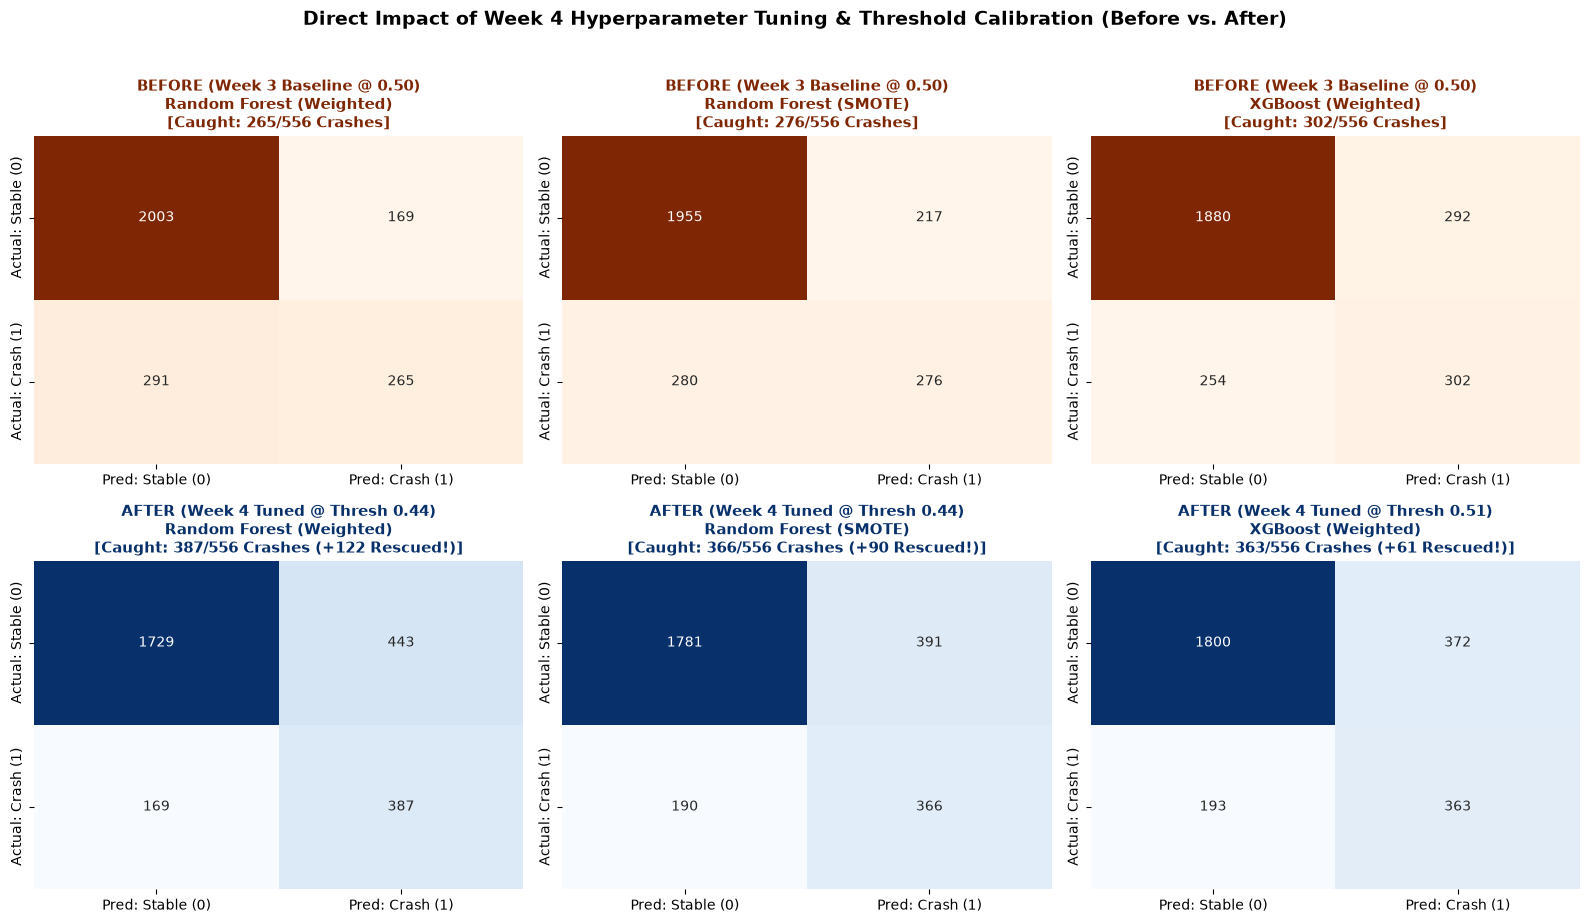

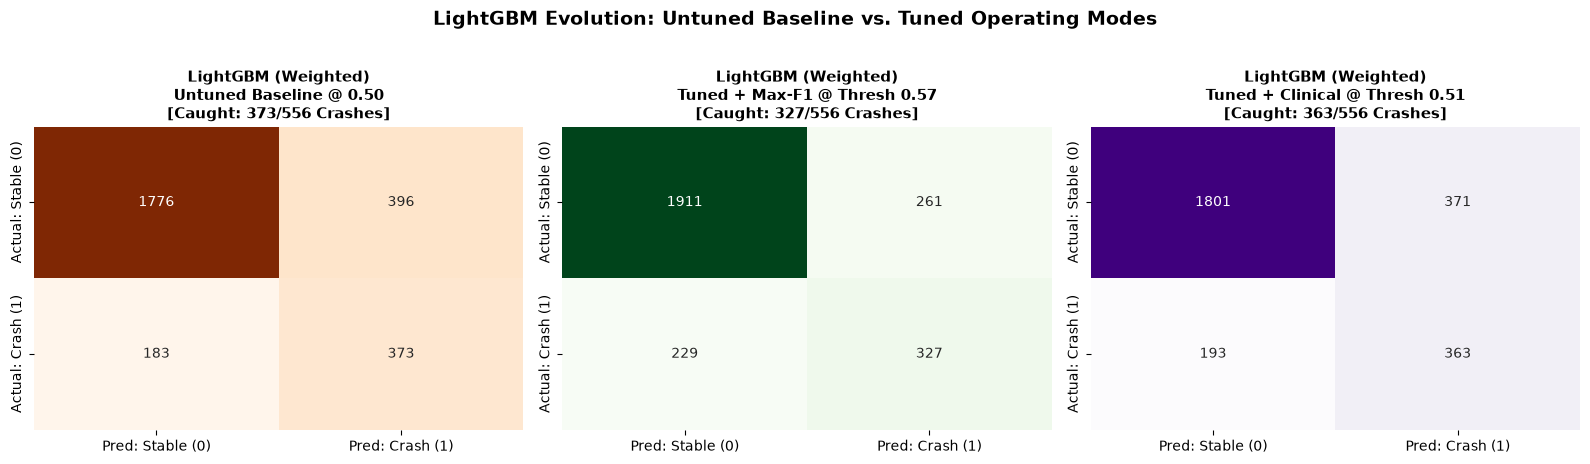

In [ ]:
# ==========================================
# CELL 4: Confusion Matrices — Before vs. After Tuning & Calibration (Includes LightGBM 3-Way Comparison)
# ==========================================
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# 1. Reconstruct exact 80/20 split to generate Week 3 "BEFORE" (Untuned Baseline @ 0.50) predictions
df = pd.read_csv("../data/processed_dataset_10.csv")
X = df.drop(columns=["Hypotension"])
y = df["Hypotension"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# Fit Week 3 Untuned Baselines (Default Parameters @ 0.50 Cutoff)
before_models = {
    "Random Forest (Weighted)": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_train, y_train),
    "Random Forest (SMOTE)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train_sm, y_train_sm),
    "XGBoost (Weighted)": XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42, n_jobs=-1).fit(X_train, y_train)
}

model_names = ["Random Forest (Weighted)",
               "Random Forest (SMOTE)", "XGBoost (Weighted)"]

# Plot 2x3 Grid: Top Row = BEFORE (Week 3 Baseline @ 0.50) | Bottom Row = AFTER (Week 4 Tuned + Calibrated)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, name in enumerate(model_names):
    # --- TOP ROW: BEFORE (Week 3 Untuned @ 0.50) ---
    y_pred_before = before_models[name].predict(X_test)
    cm_before = confusion_matrix(y_test, y_pred_before)
    sns.heatmap(
        cm_before, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[0, col],
        xticklabels=["Pred: Stable (0)", "Pred: Crash (1)"],
        yticklabels=["Actual: Stable (0)", "Actual: Crash (1)"]
    )
    caught_before = cm_before[1, 1]
    axes[0, col].set_title(
        f"BEFORE (Week 3 Baseline @ 0.50)\n{name}\n[Caught: {caught_before}/556 Crashes]",
        fontsize=11, fontweight="bold", color="#7f2704"
    )

    # --- BOTTOM ROW: AFTER (Week 4 Tuned + Clinical Threshold) ---
    thresh = bundle["models"][name]["clinical_threshold"]
    y_prob_after = bundle["models"][name]["y_prob_test"]
    y_pred_after = (y_prob_after >= thresh).astype(int)
    cm_after = confusion_matrix(y_test, y_pred_after)
    sns.heatmap(
        cm_after, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, col],
        xticklabels=["Pred: Stable (0)", "Pred: Crash (1)"],
        yticklabels=["Actual: Stable (0)", "Actual: Crash (1)"]
    )
    caught_after = cm_after[1, 1]
    diff = caught_after - caught_before
    axes[1, col].set_title(
        f"AFTER (Week 4 Tuned @ Thresh {thresh:.2f})\n{name}\n[Caught: {caught_after}/556 Crashes (+{diff} Rescued!)]",
        fontsize=11, fontweight="bold", color="#08306b"
    )

plt.suptitle("Direct Impact of Week 4 Hyperparameter Tuning & Threshold Calibration (Before vs. After)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- PLOT 2: LightGBM 3-Way Comparison (Consistent Title Styling with Thresholds) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

lgbm_data = bundle["models"]["LightGBM (Weighted)"]
lgbm_untuned = LGBMClassifier(n_estimators=100, scale_pos_weight=pos_weight,
                              random_state=42, n_jobs=-1, verbose=-1).fit(X_train, y_train)
y_pred_lgbm_base = lgbm_untuned.predict(X_test)

lightgbm_configs = [
    ("Untuned Baseline @ 0.50", y_pred_lgbm_base, "Oranges"),
    (f"Tuned + Max-F1 @ Thresh {lgbm_data['opt_f1_threshold']:.2f}",
     (lgbm_data["y_prob_test"] >= lgbm_data["opt_f1_threshold"]).astype(int), "Greens"),
    (f"Tuned + Clinical @ Thresh {lgbm_data['clinical_threshold']:.2f}",
     (lgbm_data["y_prob_test"] >= lgbm_data["clinical_threshold"]).astype(int), "Purples")
]

for ax, (mode_label, preds, cmap) in zip(axes, lightgbm_configs):
    cm_lgbm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm_lgbm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
        xticklabels=["Pred: Stable (0)", "Pred: Crash (1)"],
        yticklabels=["Actual: Stable (0)", "Actual: Crash (1)"]
    )
    ax.set_title(
        f"LightGBM (Weighted)\n{mode_label}\n[Caught: {cm_lgbm[1, 1]}/556 Crashes]",
        fontsize=11, fontweight="bold"
    )

plt.suptitle("LightGBM Evolution: Untuned Baseline vs. Tuned Operating Modes",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()